In [1]:
from google.colab import files

uploaded = files.upload()

Saving AmesHousing.csv to AmesHousing.csv


In [2]:
!pip install -q xgboost

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import joblib
import json
import warnings

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("AmesHousing.csv")

print("Dataset Shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(20)
)

print("\nDuplicate rows:", df.duplicated().sum())

Dataset Shape: (2930, 82)

First five rows:


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   objec

,0
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Qual,159
Garage Yr Blt,159
Garage Cond,159



Duplicate rows: 0


SalePrice statistics:


,SalePrice
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000



Missing SalePrice values: 0


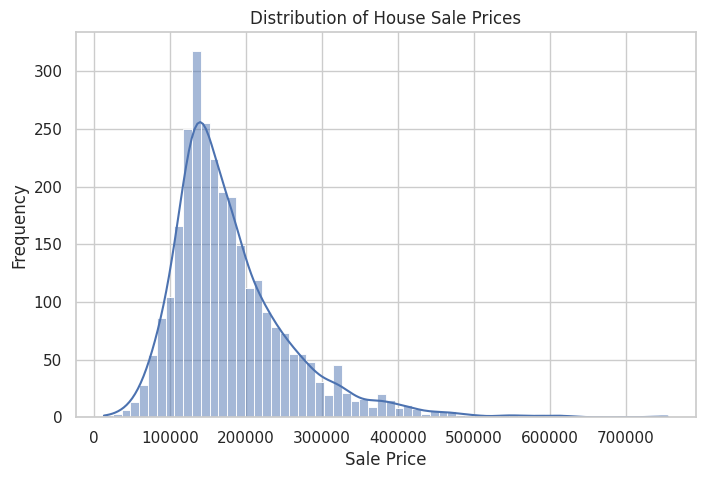

In [5]:
print("SalePrice statistics:")
display(df["SalePrice"].describe())

print(
    "\nMissing SalePrice values:",
    df["SalePrice"].isnull().sum()
)

plt.figure(figsize=(8, 5))

sns.histplot(df["SalePrice"], kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

In [6]:
# Remove rows without a target value
df = df.dropna(subset=["SalePrice"]).copy()

# Separate target and input features
X_initial = df.drop(columns=["SalePrice"]).copy()
y = df["SalePrice"].copy()

# Remove identifiers
X_initial = X_initial.drop(
    columns=["Order", "PID"],
    errors="ignore"
)

# Create the holdout split
X_train_initial, X_test_initial, y_train, y_test = train_test_split(
    X_initial,
    y,
    test_size=0.20,
    random_state=42
)

# Analyze numeric correlations using training data only
numeric_train = X_train_initial.select_dtypes(
    include=np.number
)

correlations = (
    numeric_train
    .assign(SalePrice=y_train)
    .corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=abs, ascending=False)
)

print("Top 15 numerical correlations with SalePrice:")
display(correlations.head(15))

Top 15 numerical correlations with SalePrice:


,SalePrice
Overall Qual,0.795298
Gr Liv Area,0.698315
Garage Cars,0.644304
Garage Area,0.633106
Total Bsmt SF,0.612256
1st Flr SF,0.607433
Year Built,0.545409
Full Bath,0.542053
Year Remod/Add,0.517653
Garage Yr Blt,0.516211


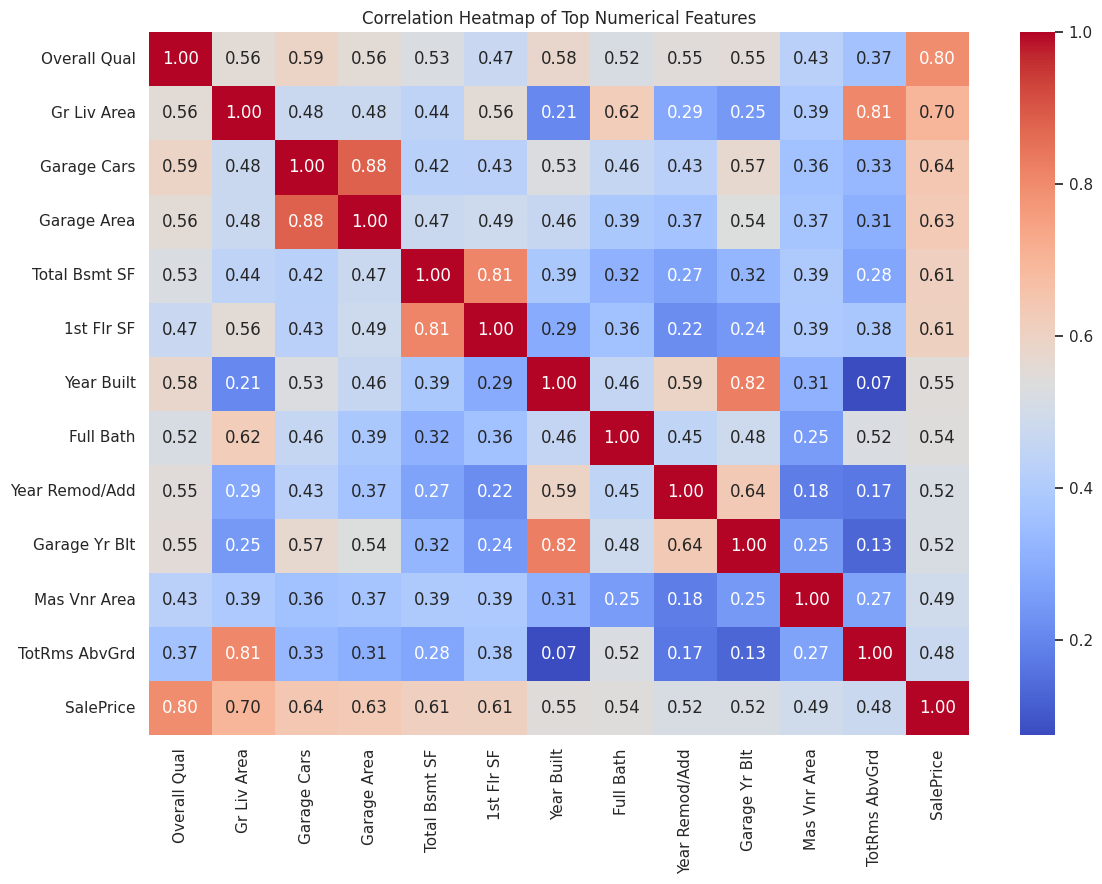

In [7]:
top_corr_features = correlations.head(12).index.tolist()

correlation_data = X_train_initial[
    top_corr_features
].copy()

correlation_data["SalePrice"] = y_train

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Top Numerical Features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

In [8]:
def create_features(data):

    data = data.copy()

    # House age
    if "Yr Sold" in data.columns and "Year Built" in data.columns:
        data["House_Age"] = (
            data["Yr Sold"] - data["Year Built"]
        ).clip(lower=0)

    # Age since remodeling
    if "Yr Sold" in data.columns and "Year Remod/Add" in data.columns:
        data["Remodel_Age"] = (
            data["Yr Sold"] - data["Year Remod/Add"]
        ).clip(lower=0)

    # Total bathrooms
    bathroom_columns = [
        "Full Bath",
        "Half Bath",
        "Bsmt Full Bath",
        "Bsmt Half Bath"
    ]

    available_bathrooms = [
        col for col in bathroom_columns
        if col in data.columns
    ]

    if available_bathrooms:
        weights = {
            "Full Bath": 1.0,
            "Half Bath": 0.5,
            "Bsmt Full Bath": 1.0,
            "Bsmt Half Bath": 0.5
        }

        data["Total_Bathrooms"] = sum(
            data[col].fillna(0) * weights[col]
            for col in available_bathrooms
        )

    # Total porch and deck area
    porch_columns = [
        "Open Porch SF",
        "Enclosed Porch",
        "3Ssn Porch",
        "Screen Porch",
        "Wood Deck SF"
    ]

    available_porch = [
        col for col in porch_columns
        if col in data.columns
    ]

    if available_porch:
        data["Total_Porch_Area"] = (
            data[available_porch].fillna(0).sum(axis=1)
        )

    # Total finished area
    finished_area_columns = [
        "Gr Liv Area",
        "BsmtFin SF 1",
        "BsmtFin SF 2"
    ]

    available_area = [
        col for col in finished_area_columns
        if col in data.columns
    ]

    if available_area:
        data["Total_Finished_Area"] = (
            data[available_area].fillna(0).sum(axis=1)
        )

    return data


X = create_features(X_initial)

print("Feature engineering completed!")
print("Original features:", X_initial.shape[1])
print("New feature count:", X.shape[1] - X_initial.shape[1])

display(X.head())

Feature engineering completed!
Original features: 79
New feature count: 5


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,House_Age,Remodel_Age,Total_Bathrooms,Total_Porch_Area,Total_Finished_Area
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,5,2010,WD,Normal,50,50,2.0,272,2295.0
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,6,2010,WD,Normal,49,49,1.0,260,1508.0
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,12500,6,2010,WD,Normal,52,52,1.5,429,2252.0
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,...,0,4,2010,WD,Normal,42,42,3.5,0,3175.0
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,3,2010,WD,Normal,13,12,2.5,246,2420.0


In [9]:
engineered_features = [
    "House_Age",
    "Remodel_Age",
    "Total_Bathrooms",
    "Total_Porch_Area",
    "Total_Finished_Area"
]

for feature in engineered_features:
    if feature in X.columns:
        print("\n", feature)
        display(X[feature].describe())


 House_Age


,House_Age
count,2930.000000
mean,36.434471
std,30.290941
min,0.000000
25%,7.000000
50%,34.000000
75%,54.000000
max,136.000000



 Remodel_Age


,Remodel_Age
count,2930.000000
mean,23.525256
std,20.857256
min,0.000000
25%,4.000000
50%,15.000000
75%,42.750000
max,60.000000



 Total_Bathrooms


,Total_Bathrooms
count,2930.000000
mean,2.217918
std,0.807444
min,1.000000
25%,1.500000
50%,2.000000
75%,2.500000
max,7.000000



 Total_Porch_Area


,Total_Porch_Area
count,2930.000000
mean,182.891468
std,159.834420
min,0.000000
25%,48.000000
50%,165.000000
75%,266.000000
max,1424.000000



 Total_Finished_Area


,Total_Finished_Area
count,2930.000000
mean,1991.874403
std,759.608884
min,334.000000
25%,1491.000000
50%,1851.500000
75%,2378.750000
max,11286.000000


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2344, 84)
Testing features: (586, 84)
Training target: (2344,)
Testing target: (586,)


In [11]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numeric features: 41
Number of categorical features: 43

Numeric features:
['MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold', 'House_Age', 'Remodel_Age', 'Total_Bathrooms', 'Total_Porch_Area', 'Total_Finished_Area']

Categorical features:
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type'

In [12]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
models = {
    "Ridge Regression": Ridge(alpha=10),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

print("Three models are ready for comparison.")

Three models are ready for comparison.


In [14]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

print("Five-fold cross-validation configured.")

Five-fold cross-validation configured.


In [15]:
results = []

trained_pipelines = {}

for model_name, model in models.items():

    print("\nTraining:", model_name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    mean_mae = -scores["test_MAE"].mean()
    std_mae = scores["test_MAE"].std()

    mean_rmse = -scores["test_RMSE"].mean()
    std_rmse = scores["test_RMSE"].std()

    mean_r2 = scores["test_R2"].mean()

    results.append({
        "Model": model_name,
        "CV_MAE": mean_mae,
        "CV_MAE_Std": std_mae,
        "CV_RMSE": mean_rmse,
        "CV_RMSE_Std": std_rmse,
        "CV_R2": mean_r2
    })

    trained_pipelines[model_name] = pipeline

    print("Mean CV MAE:", round(mean_mae, 2))
    print("Mean CV RMSE:", round(mean_rmse, 2))
    print("Mean CV R2:", round(mean_r2, 4))


comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="CV_MAE",
    ascending=True
).reset_index(drop=True)

display(comparison_df)


Training: Ridge Regression
Mean CV MAE: 16463.24
Mean CV RMSE: 29397.33
Mean CV R2: 0.8406

Training: Random Forest
Mean CV MAE: 15810.82
Mean CV RMSE: 26402.92
Mean CV R2: 0.8768

Training: XGBoost
Mean CV MAE: 14324.07
Mean CV RMSE: 24506.47
Mean CV R2: 0.8932


,Model,CV_MAE,CV_MAE_Std,CV_RMSE,CV_RMSE_Std,CV_R2
0,XGBoost,14324.072461,1358.369532,24506.466406,6109.046596,0.893209
1,Random Forest,15810.823195,1569.485065,26402.924992,6071.441643,0.876836
2,Ridge Regression,16463.238583,1055.233786,29397.331637,9296.855232,0.840593


In [16]:
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison report saved!")

Model comparison report saved!


In [17]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best model from cross-validation:", best_model_name)

best_base_model = models[best_model_name]

Best model from cross-validation: XGBoost


In [19]:
tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", best_base_model)
    ]
)

In [20]:
if best_model_name == "Ridge Regression":

    param_distributions = {
        "model__alpha": [0.1, 1, 5, 10, 20, 50, 100]
    }

elif best_model_name == "Random Forest":

    param_distributions = {
        "model__n_estimators": [200, 300, 400, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.7, 1.0]
    }

else:

    param_distributions = {
        "model__n_estimators": [200, 300, 400, 500],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.7, 0.8, 0.9, 1.0],
        "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
    }

print("Parameter search space prepared.")

Parameter search space prepared.


In [21]:
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("\nBest parameters:")
print(random_search.best_params_)

print(
    "\nBest cross-validation MAE:",
    round(-random_search.best_score_, 2)
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best parameters:
{'model__subsample': 0.9, 'model__n_estimators': 400, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}

Best cross-validation MAE: 14203.91


In [22]:
best_model = random_search.best_estimator_

In [23]:
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("Optimized Model Results")
print("-----------------------")
print("Selected Model:", best_model_name)
print("Test MAE: $", round(mae, 2))
print("Test RMSE: $", round(rmse, 2))
print("Test R2:", round(r2, 4))

Optimized Model Results
-----------------------
Selected Model: XGBoost
Test MAE: $ 13603.27
Test RMSE: $ 23023.79
Test R2: 0.9339


In [24]:
baseline_mae = 17309.70

improvement = (
    (baseline_mae - mae) / baseline_mae
) * 100

print("Task 1 Baseline MAE: $", baseline_mae)
print("Task 2 Optimized MAE: $", round(mae, 2))

print(
    "MAE improvement:",
    round(improvement, 2),
    "%"
)

if improvement > 0:
    print("Task 2 improved over the baseline.")
elif improvement < 0:
    print("Task 2 did not outperform the baseline yet.")
else:
    print("Task 2 matched the baseline.")

Task 1 Baseline MAE: $ 17309.7
Task 2 Optimized MAE: $ 13603.27
MAE improvement: 21.41 %
Task 2 improved over the baseline.


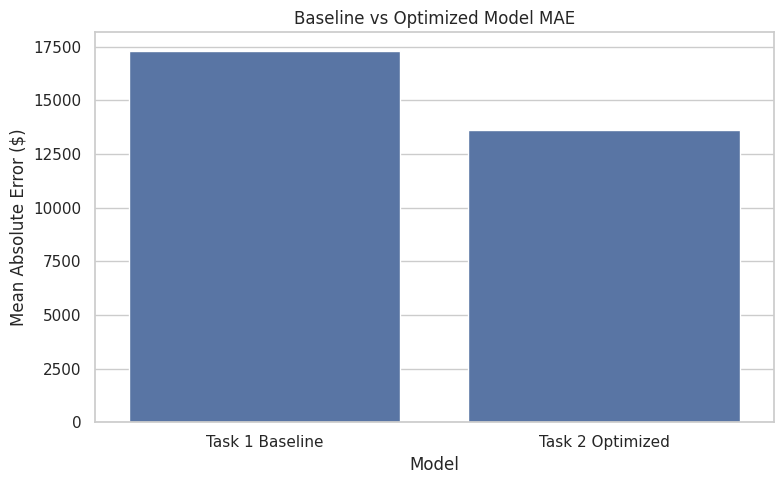

In [25]:
plt.figure(figsize=(8, 5))

labels = [
    "Task 1 Baseline",
    "Task 2 Optimized"
]

values = [
    baseline_mae,
    mae
]

sns.barplot(
    x=labels,
    y=values
)

plt.title("Baseline vs Optimized Model MAE")
plt.ylabel("Mean Absolute Error ($)")
plt.xlabel("Model")

plt.tight_layout()

plt.savefig(
    "baseline_vs_optimized.png",
    dpi=300
)

plt.show()

In [26]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 5 Important Features:")
display(importance_df.head(5))

Top 5 Important Features:


,Feature,Importance,Importance_Std
0,Overall Qual,14353.947461,416.636326
1,Total_Finished_Area,8537.694727,461.045263
2,Gr Liv Area,3926.581836,204.380680
3,Year Built,1668.580957,219.975970
4,Lot Area,1351.370312,123.811047


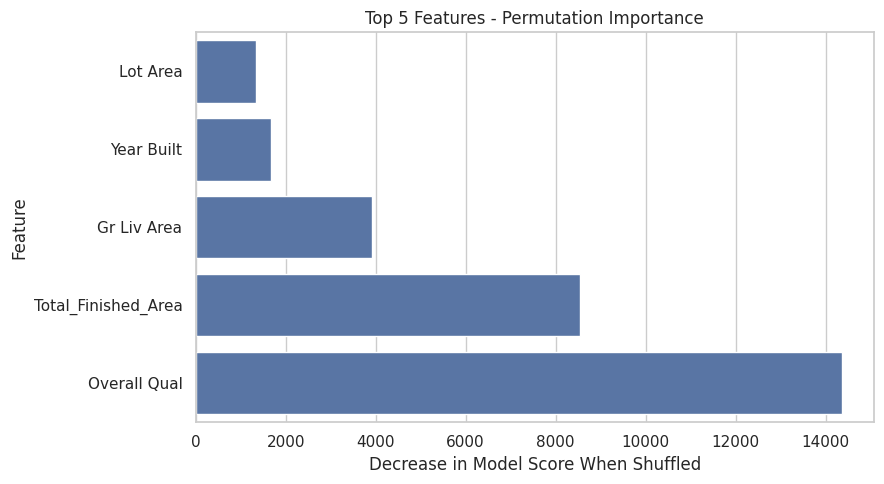

In [27]:
top_5 = importance_df.head(5).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_5,
    x="Importance",
    y="Feature"
)

plt.title("Top 5 Features - Permutation Importance")
plt.xlabel("Decrease in Model Score When Shuffled")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    "top_5_feature_importance.png",
    dpi=300
)

plt.show()

In [28]:
importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance report saved!")

Feature importance report saved!


In [29]:
joblib.dump(
    best_model,
    "urbannest_best_model.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!


In [30]:
loaded_model = joblib.load(
    "urbannest_best_model.joblib"
)

sample_predictions = loaded_model.predict(
    X_test.head(5)
)

print("Predictions from saved model:")
print(sample_predictions)

print("\nActual prices:")
print(y_test.head(5).values)

Predictions from saved model:
[173832.78  103450.22  190518.92  123813.05  117116.305]

Actual prices:
[161000 116000 196500 123600 126000]


In [31]:
final_report = {
    "project": "UrbanNest Advanced Model Optimization",
    "selected_model": best_model_name,
    "baseline_mae": float(baseline_mae),
    "optimized_test_mae": float(mae),
    "optimized_test_rmse": float(rmse),
    "optimized_test_r2": float(r2),
    "mae_improvement_percent": float(improvement),
    "best_parameters": {
        key: str(value)
        for key, value in random_search.best_params_.items()
    },
    "top_5_features": importance_df.head(5)["Feature"].tolist()
}

with open(
    "final_results.json",
    "w"
) as file:

    json.dump(
        final_report,
        file,
        indent=4
    )

print("Final results JSON saved!")

Final results JSON saved!


In [32]:
with open("final_results.txt", "w") as file:

    file.write("URBANNEST - TASK 2 RESULTS\n")
    file.write("==========================\n\n")

    file.write(f"Selected Model: {best_model_name}\n")
    file.write(f"Baseline MAE: ${baseline_mae:,.2f}\n")
    file.write(f"Optimized Test MAE: ${mae:,.2f}\n")
    file.write(f"Optimized Test RMSE: ${rmse:,.2f}\n")
    file.write(f"Optimized Test R2: {r2:.4f}\n")
    file.write(f"MAE Improvement: {improvement:.2f}%\n\n")

    file.write("TOP 5 IMPORTANT FEATURES\n")
    file.write("------------------------\n")

    for _, row in importance_df.head(5).iterrows():
        file.write(
            f"{row['Feature']}: {row['Importance']:.6f}\n"
        )

print("Readable results report saved!")

Readable results report saved!


In [33]:
project_dir = "UrbanNest-Model-Optimization"

os.makedirs(project_dir, exist_ok=True)

print("Project directory created!")

Project directory created!


In [34]:
import shutil

files_to_copy = [
    "urbannest_best_model.joblib",
    "model_comparison.csv",
    "feature_importance.csv",
    "final_results.json",
    "final_results.txt",
    "correlation_heatmap.png",
    "baseline_vs_optimized.png",
    "top_5_feature_importance.png"
]

for filename in files_to_copy:

    if os.path.exists(filename):

        shutil.copy(
            filename,
            os.path.join(project_dir, filename)
        )

        print("Copied:", filename)

    else:
        print("File not found:", filename)

Copied: urbannest_best_model.joblib
Copied: model_comparison.csv
Copied: feature_importance.csv
Copied: final_results.json
Copied: final_results.txt
Copied: correlation_heatmap.png
Copied: baseline_vs_optimized.png
Copied: top_5_feature_importance.png


In [35]:
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
xgboost
joblib
"""

with open(
    os.path.join(project_dir, "requirements.txt"),
    "w"
) as file:

    file.write(requirements.strip())

print("requirements.txt created!")

requirements.txt created!


In [36]:
shutil.make_archive(
    "UrbanNest-Model-Optimization",
    "zip",
    project_dir
)

print("Project ZIP created!")

Project ZIP created!
